# Study 6: fitted per-feature linking functions

The study-6 counterpart of `study9-linking-functions.ipynb`: the per-feature Beta-mixture **linking
function** for each of the 16 test features, at the posterior-median θ of the study-6 full fit on the
**preregistered** data (ls ≈ 1.79, speaker β ≈ 29).

Three conditions: **generic** (heard a generic about every training feature), **specific** (heard a
specific statement about every training feature), **baseline** (heard nothing).

For feature j in condition c, a rating r is modeled as

    r ~ pz1[c, j] * Beta(a_kl[j], b_kl[j])  +  (1 - pz1[c, j]) * Beta(a_nkl[j], b_nkl[j])

with per-feature linking shapes shared across conditions, and pz1 = the ratings-free GP coherence
P(kind-linked) predicted from that condition's training statements (`inference.prior_pz1_modes`).

**Where the fit comes from.** `results/study6-fit/` was deleted in commit `333c035`. This notebook
reads the fit directly from git at `333c035~1` (nothing is restored to `results/`, so
`run_parameter_estimation.py study6` will still refit it). Section 6 checks that the current code
reproduces that fit's shapes and predictions exactly.

In [3]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import io
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
from scipy.stats import beta as sbeta
from scipy.integrate import quad

import inference as inf
import studies68 as s68

FIT_COMMIT = '333c035~1'
FIT_DIR = 'model/per-feature-prevalence/results/study6-fit'

def git_file(name):
    """Bytes of results/study6-fit/<name> as of FIT_COMMIT."""
    out = subprocess.run(['git', 'show', f'{FIT_COMMIT}:{FIT_DIR}/{name}'],
                         capture_output=True, check=True)
    return io.BytesIO(out.stdout)

geom, responses_cond = s68.load_study6_prereg()
CONDS = list(responses_cond)                      # generic, specific, baseline
features = geom['test_feature_names']
trait = geom['test_trait']
J = len(features)
R = {c: np.asarray(responses_cond[c]) for c in CONDS}   # loader nudges exact 0/1 half a bin inward
emp = {c: R[c].mean(0) for c in CONDS}
print({c: R[c].shape[0] for c in CONDS}, "participants per condition")

z = np.load(git_file('fitted-link-shapes.npz'), allow_pickle=True)
assert [str(f) for f in z['feature_names']] == features
shapes = np.asarray(z['shapes'])
LS, MU, SIG, BETA_SPK = [float(v) for v in z['theta']]
pz1 = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, LS, MU, SIG, beta_speaker=BETA_SPK).items()}
a_kl, b_kl, a_nkl, b_nkl = shapes.T
mean_kl, mean_nkl = a_kl / (a_kl + b_kl), a_nkl / (a_nkl + b_nkl)
pred = {c: pz1[c] * mean_kl + (1 - pz1[c]) * mean_nkl for c in CONDS}
print(f"study-6 fit ({FIT_COMMIT}): ls={LS:.3f}  mu_0={MU:+.3f}  sigma={SIG:.3f}  speaker beta={BETA_SPK:.3f}")

load_study6_prereg: 446 of 471 rows kept after exclusions
{'generic': 148, 'specific': 146, 'baseline': 152} participants per condition
study-6 fit (333c035~1): ls=1.794  mu_0=+0.127  sigma=2.079  speaker beta=29.071


In [10]:
# shared plotting setup: one fixed color per condition, reused in every figure
COND_COLOR = {'generic': '#2a78d6', 'specific': '#eb6834', 'baseline': '#1baf7a'}
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2,
    'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 8, 'legend.frameon': False,
})

X = np.linspace(0.005, 0.995, 400)
BINS = np.linspace(0, 1, 21)

def kl_pdf(j):  return sbeta.pdf(X, a_kl[j], b_kl[j])
def nkl_pdf(j): return sbeta.pdf(X, a_nkl[j], b_nkl[j])
def mix_pdf(j, p): return p * kl_pdf(j) + (1 - p) * nkl_pdf(j)

def ycap(j, hist_max):
    # components with a,b < 1 diverge at 0 and 1: cap the axis at the
    # histogram / bump, not at the edge spike
    return 1.25 * max(hist_max, nkl_pdf(j).max(), 1.0)

def style(ax):
    ax.set_xlim(0, 1)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)

## 1. Linking shapes per feature

`kl U-shaped` flags components with a < 1 and b < 1 (density piled up at 0 **and** 1). `pz1 range` is
the spread of the coherence across the 3 conditions.

In [11]:
pz1_mat = np.stack([pz1[c] for c in CONDS])
pd.DataFrame({
    'feature': features, 'trait': trait,
    'a_kl': a_kl, 'b_kl': b_kl, 'mean_kl': mean_kl,
    'a_nkl': a_nkl, 'b_nkl': b_nkl, 'mean_nkl': mean_nkl,
    'kl U-shaped': (a_kl < 1) & (b_kl < 1),
    **{f'pz1 {c}': pz1[c] for c in CONDS},
    'pz1 range': np.ptp(pz1_mat, axis=0),
}).round(3)

,feature,trait,a_kl,b_kl,mean_kl,a_nkl,b_nkl,mean_nkl,kl U-shaped,pz1 generic,pz1 specific,pz1 baseline,pz1 range
0,chug maple syrup,hobbies_behaviors,0.434,0.336,0.563,0.647,2.008,0.244,True,0.879,0.051,0.532,0.828
1,clap three times before entering a room,hobbies_behaviors,0.548,0.359,0.604,0.568,1.746,0.246,True,0.880,0.049,0.532,0.831
2,dance around a fire on their 10th birthday,beliefs_culture,0.736,0.348,0.679,0.616,1.027,0.375,True,0.884,0.047,0.532,0.837
3,farm potatoes,hobbies_behaviors,0.603,0.444,0.576,1.182,2.509,0.320,True,0.881,0.049,0.532,0.832
4,go to the opera,hobbies_behaviors,0.571,0.517,0.525,1.085,2.942,0.269,True,0.878,0.051,0.532,0.827
5,live in caves,hobbies_behaviors,0.472,0.361,0.567,0.635,1.823,0.258,True,0.884,0.047,0.532,0.837
6,look to their left when spoken to,hobbies_behaviors,0.576,0.406,0.586,0.954,2.006,0.322,True,0.883,0.048,0.532,0.835
7,paint their hands yellow,hobbies_behaviors,0.513,0.373,0.579,0.681,1.982,0.256,True,0.884,0.047,0.532,0.838
8,play banjos,hobbies_behaviors,0.572,0.505,0.531,1.138,3.592,0.241,True,0.880,0.050,0.532,0.831
9,ride lions,hobbies_behaviors,0.344,0.356,0.492,0.533,2.813,0.159,True,0.883,0.047,0.532,0.836


## 2. All conditions pooled

Grey bars: that feature's ratings pooled over all participants. Dashed: the two linking components
(dark = kl, light = nkl). Colored: the mixture each condition predicts, using its own pz1. Ticks along
the bottom are each condition's **empirical** mean rating.

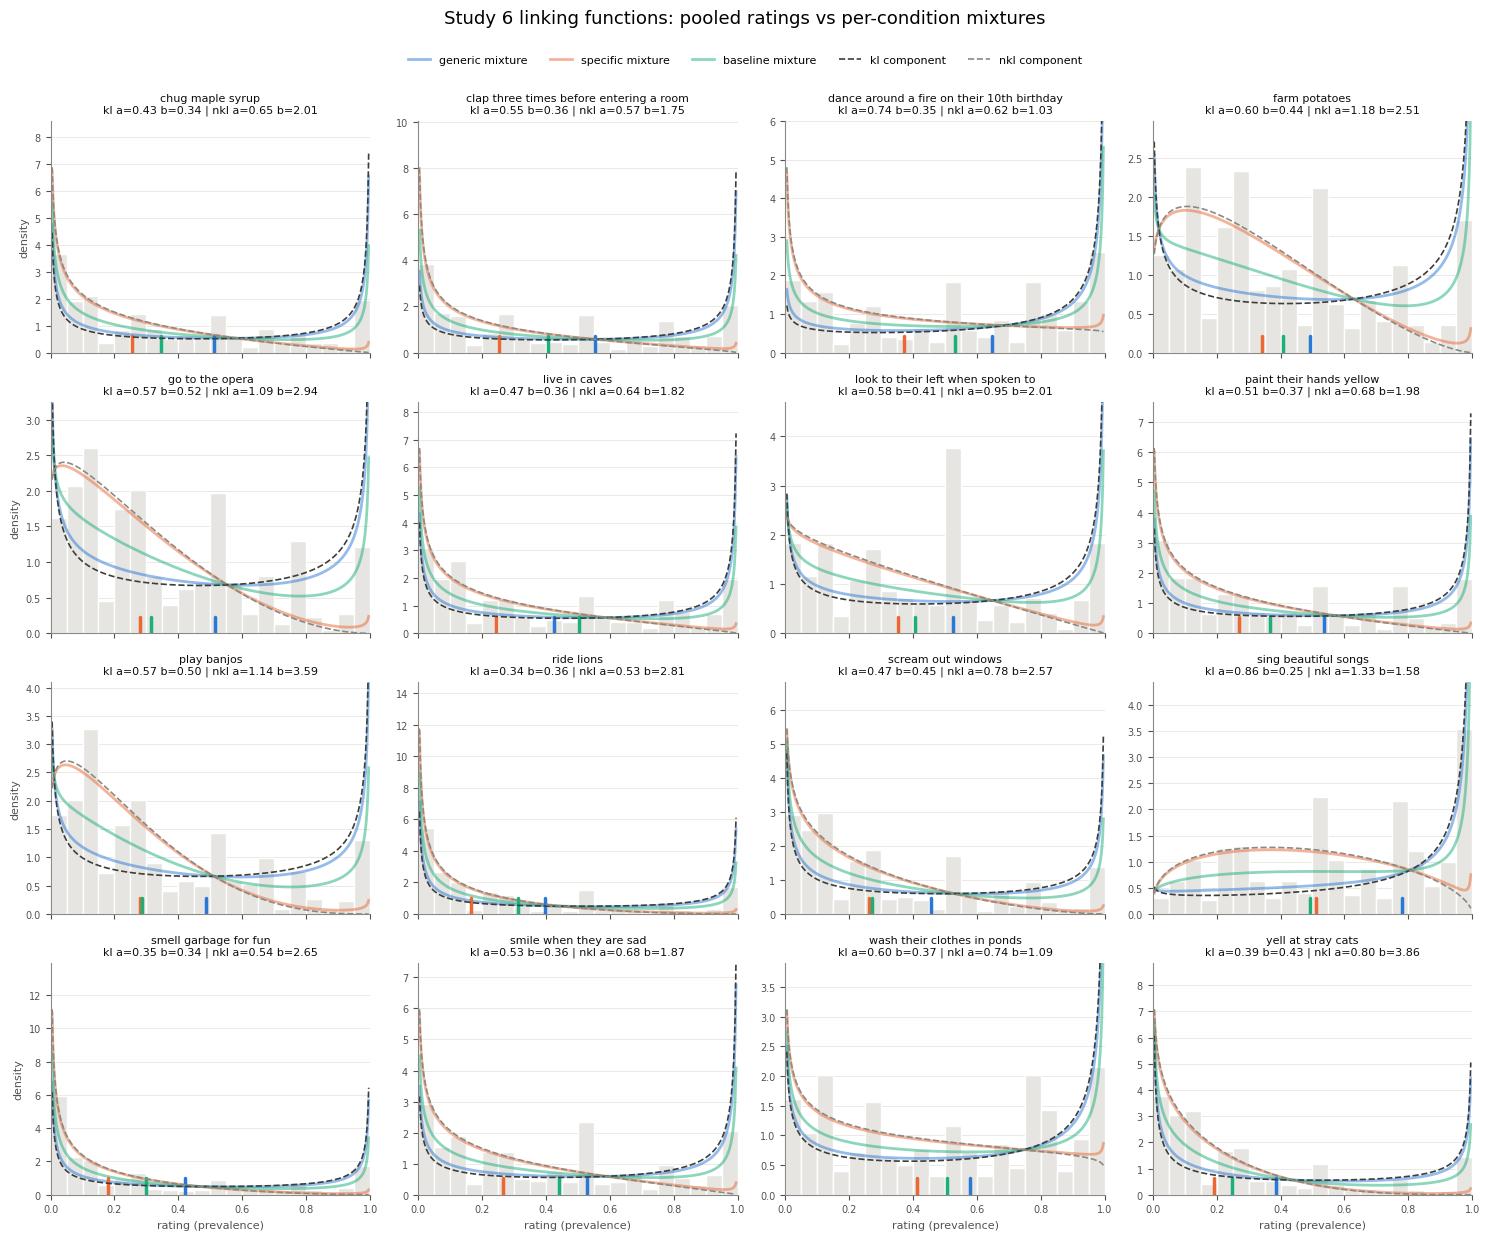

In [16]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12), sharex=True)
for j, ax in enumerate(axes.ravel()):
    r_all = np.concatenate([R[c][:, j] for c in CONDS])
    h = ax.hist(r_all, bins=BINS, density=True, color=GRID, edgecolor='white', linewidth=1)[0]
    
    for c in CONDS:
        ax.plot(X, mix_pdf(j, pz1[c][j]), color=COND_COLOR[c], lw=2, label=f'{c} mixture',  alpha=.5)
    top = ycap(j, h.max())
    for c in CONDS:
        ax.plot([emp[c][j]] * 2, [0, 0.07 * top], color=COND_COLOR[c], lw=2.5, solid_capstyle='round')
    ax.plot(X, kl_pdf(j),  '--', color='#3d3d3a', lw=1.2, label='kl component')
    ax.plot(X, nkl_pdf(j), '--', color=MUTED,     lw=1.2, label='nkl component')
    ax.set_ylim(0, top); style(ax)
    ax.set_title(f"{features[j]}\nkl a={a_kl[j]:.2f} b={b_kl[j]:.2f} | nkl a={a_nkl[j]:.2f} b={b_nkl[j]:.2f}",
                 color=TEXT_1, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('rating (prevalence)')
for ax in axes[:, 0]:
    ax.set_ylabel('density')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.0))
fig.suptitle('Study 6 linking functions: pooled ratings vs per-condition mixtures', y=1.03, fontsize=13)
fig.tight_layout()
plt.show()

## 3. Per condition

Each column is one condition: its own participants' ratings (bars) against its own mixture (line). Solid
vertical line = predicted mean, dotted = empirical mean. Two figures of 8 features each.

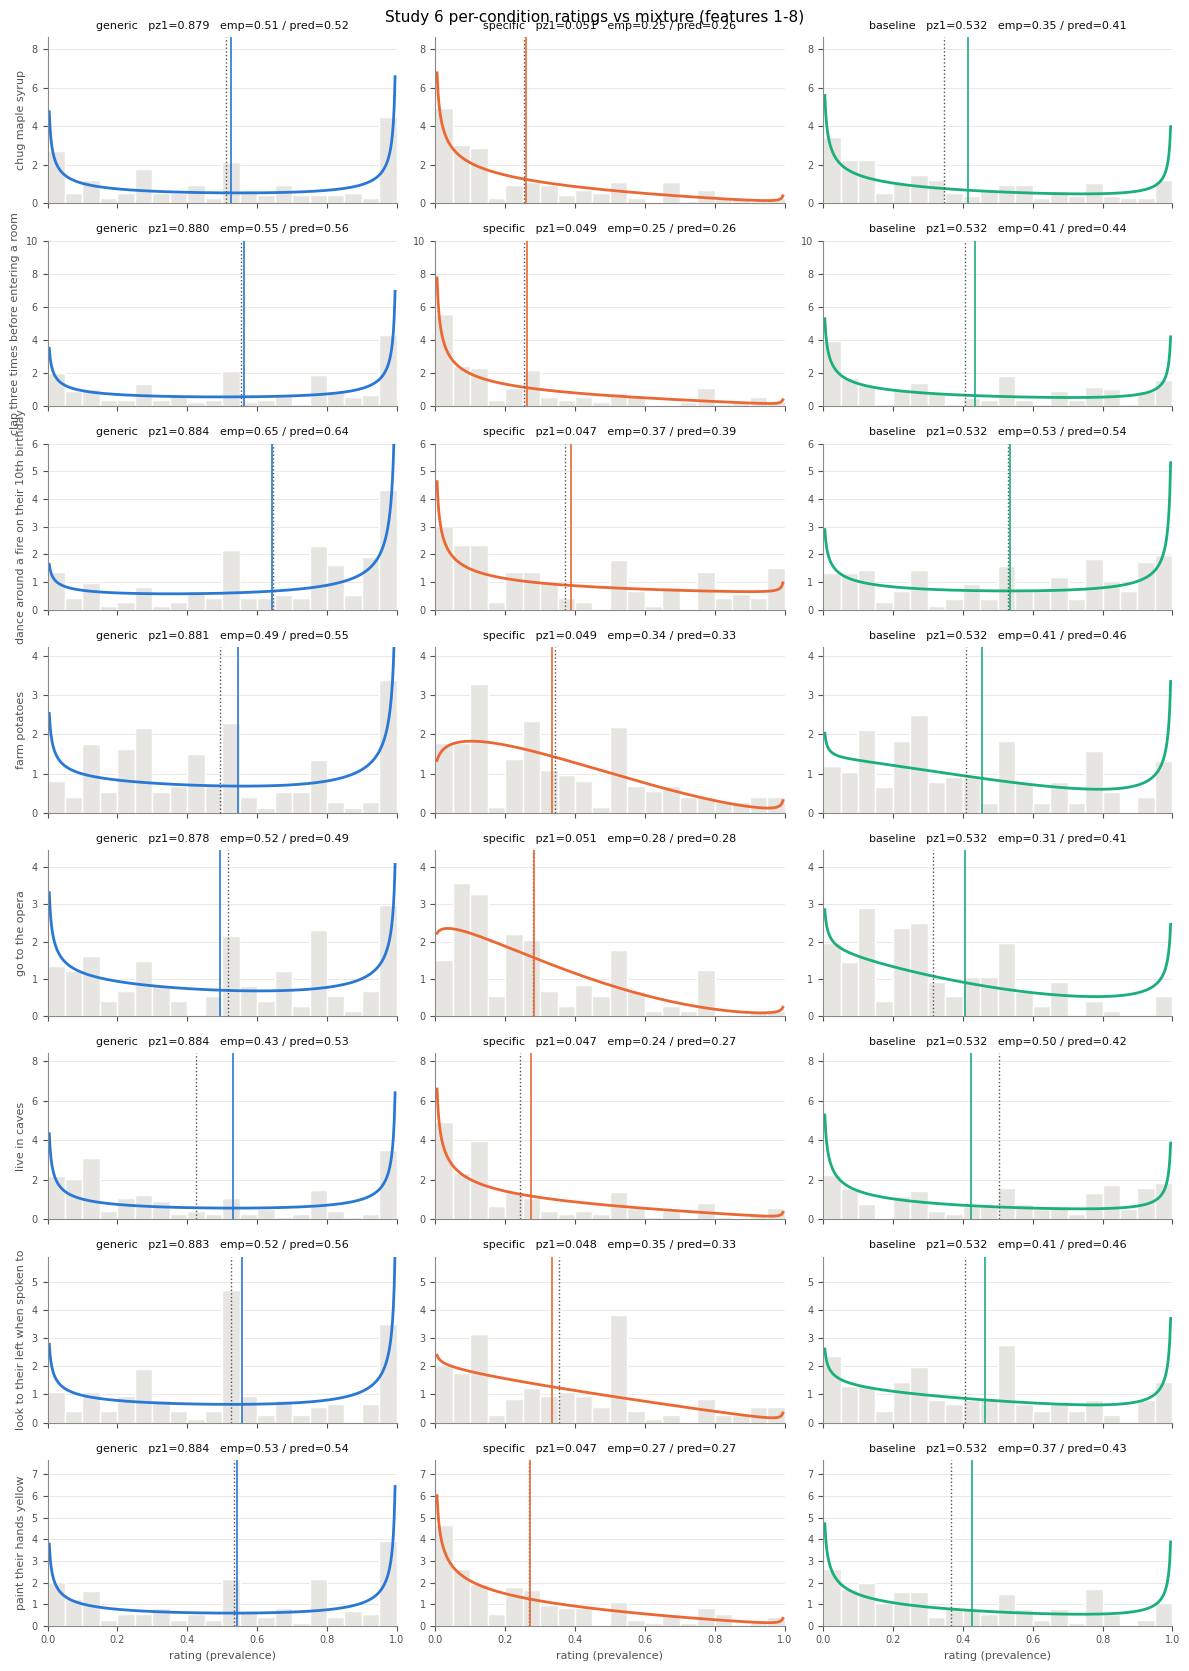

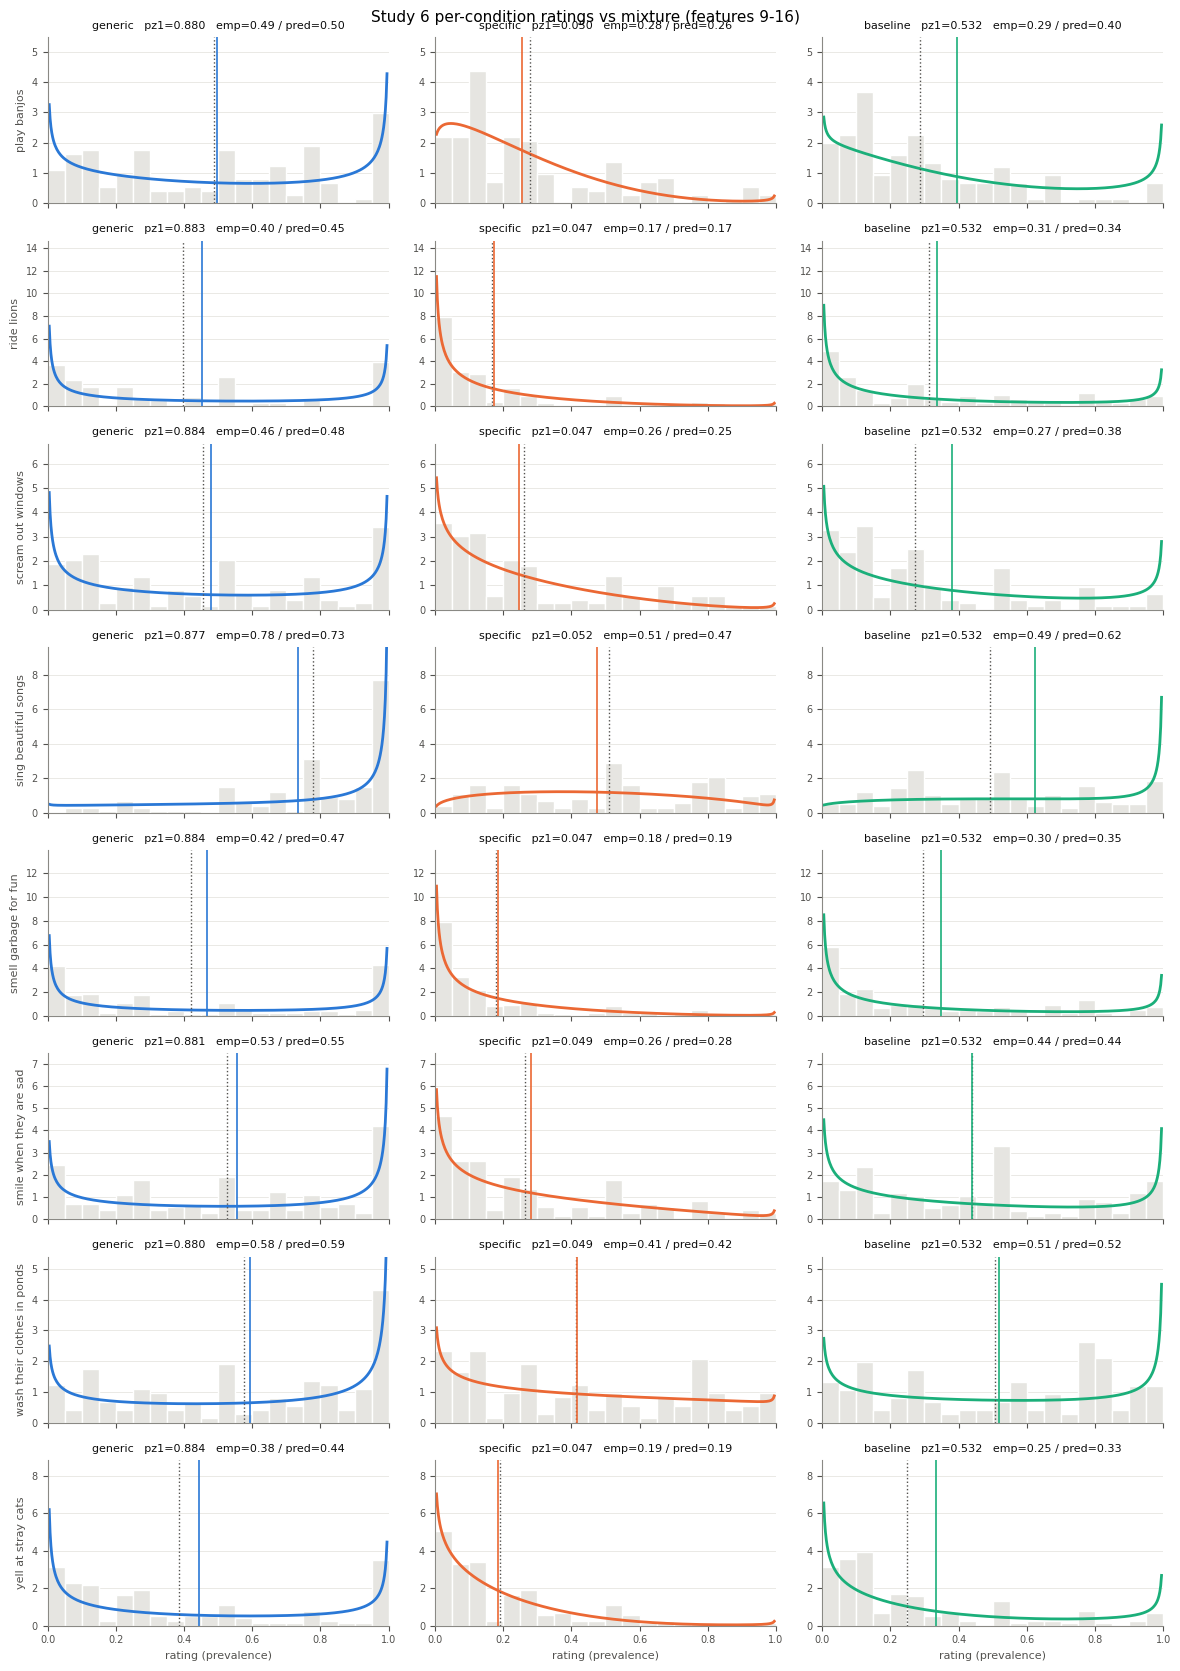

In [5]:
for half in (range(0, 8), range(8, 16)):
    fig, axes = plt.subplots(8, 3, figsize=(12, 17), sharex=True)
    for r, j in enumerate(half):
        tops = []
        for k, c in enumerate(CONDS):
            ax = axes[r, k]
            h = ax.hist(R[c][:, j], bins=BINS, density=True, color=GRID, edgecolor='white', linewidth=1)[0]
            ax.plot(X, mix_pdf(j, pz1[c][j]), color=COND_COLOR[c], lw=2)
            ax.axvline(emp[c][j], color=TEXT_2, lw=1, ls=':')
            ax.axvline(pred[c][j], color=COND_COLOR[c], lw=1.2)
            ax.set_title(f"{c}   pz1={pz1[c][j]:.3f}   emp={emp[c][j]:.2f} / pred={pred[c][j]:.2f}",
                         color=TEXT_1, fontsize=8)
            tops.append(ycap(j, h.max()))
        for k in range(3):
            axes[r, k].set_ylim(0, max(tops)); style(axes[r, k])
        axes[r, 0].set_ylabel(features[j], color=TEXT_2, fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel('rating (prevalence)')
    fig.suptitle(f"Study 6 per-condition ratings vs mixture (features {half.start + 1}-{half.stop})", fontsize=11)
    fig.tight_layout()
    plt.show()

## 4. What the linking function fixes vs what coherence can move

For each feature the grey bar spans the two component means (nkl ○ to kl ●). A condition's predicted mean
always sits on that bar, so the **bar's position** is set by the linking function and **where along it**
each condition lands is set by the coherence field. Filled dots = predicted mean; hollow diamonds =
empirical mean.

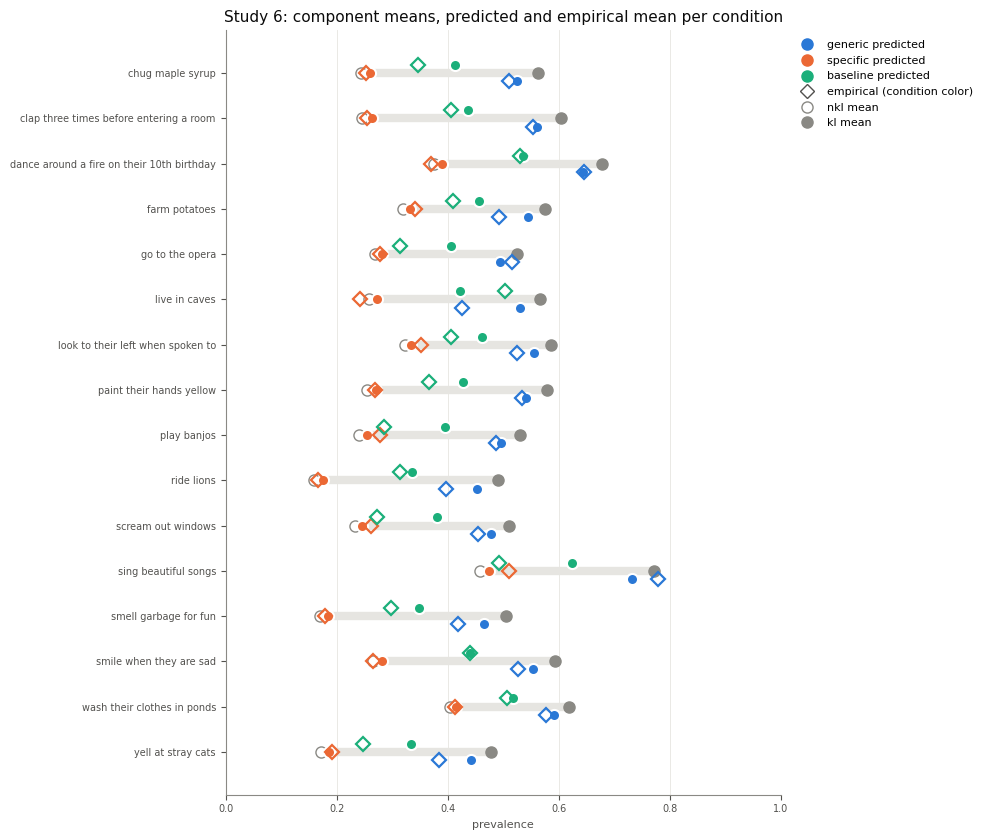

In [6]:
fig, ax = plt.subplots(figsize=(10, 8.5))
order = list(range(J))[::-1]
for y, j in enumerate(order):
    ax.plot([mean_nkl[j], mean_kl[j]], [y, y], color=GRID, lw=6, solid_capstyle='round', zorder=1)
    ax.plot(mean_nkl[j], y, 'o', mfc='white', mec=MUTED, ms=8, zorder=2)
    ax.plot(mean_kl[j],  y, 'o', color=MUTED, ms=8, zorder=2)
    for k, c in enumerate(CONDS):
        dy = (k - 1) * 0.18
        ax.plot(pred[c][j], y + dy, 'o', color=COND_COLOR[c], ms=8, mec='white', mew=1.5, zorder=3)
        ax.plot(emp[c][j], y + dy, 'D', mfc='none', mec=COND_COLOR[c], ms=7, mew=1.6, zorder=3)
ax.set_yticks(range(J)); ax.set_yticklabels([features[j] for j in order])
ax.set_xlim(0, 1); ax.set_xlabel('prevalence')
ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
leg = [Line2D([], [], marker='o', ls='', color=COND_COLOR[c], ms=8, label=f'{c} predicted') for c in CONDS]
leg += [Line2D([], [], marker='D', ls='', mfc='none', mec=TEXT_2, ms=7, label='empirical (condition color)'),
        Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED, ms=8, label='nkl mean'),
        Line2D([], [], marker='o', ls='', color=MUTED, ms=8, label='kl mean')]
ax.legend(handles=leg, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Study 6: component means, predicted and empirical mean per condition', color=TEXT_1, fontsize=11)
fig.tight_layout()
plt.show()

In [7]:
# table view of the same numbers (color is the only identity cue in the plot)
pd.DataFrame([{'feature': features[j], 'condition': c, 'pz1': pz1[c][j],
               'pred_mean': pred[c][j], 'emp_mean': emp[c][j]}
              for j in range(J) for c in CONDS]
             ).pivot_table(index='feature', columns='condition',
                           values=['pred_mean', 'emp_mean']).round(3)

emp_mean                   \
condition                                  baseline generic specific   
feature                                                                
chug maple syrup                              0.346   0.510    0.254   
clap three times before entering a room       0.406   0.554    0.254   
dance around a fire on their 10th birthday    0.531   0.645    0.371   
farm potatoes                                 0.409   0.493    0.341   
go to the opera                               0.314   0.515    0.278   
live in caves                                 0.503   0.426    0.243   
look to their left when spoken to             0.406   0.524    0.353   
paint their hands yellow                      0.367   0.535    0.269   
play banjos                                   0.286   0.487    0.279   
ride lions                                    0.314   0.398    0.167   
scream out windows                            0.272   0.456    0.261   
sing beautiful songs                          0.493   0.779    0.510   
smell garbage for fun                         0.297   0.419    0.180   
smile when they are sad                       0.440   0.527    0.265   
wash their clothes in ponds                   0.507   0.577    0.413   
yell at stray cats                            0.248   0.385    0.192   

                                           pred_mean                   
condition                                   baseline generic specific  
feature                                                                
chug maple syrup                               0.414   0.525    0.260  
clap three times before entering a room        0.436   0.561    0.263  
dance around a fire on their 10th birthday     0.537   0.644    0.389  
farm potatoes                                  0.456   0.546    0.333  
go to the opera                                0.405   0.494    0.283  
live in caves                                  0.422   0.531    0.273  
look to their left when spoken to              0.463   0.556    0.335  
paint their hands yellow                       0.428   0.542    0.271  
play banjos                                    0.395   0.497    0.255  
ride lions                                     0.336   0.453    0.175  
scream out windows                             0.381   0.479    0.246  
sing beautiful songs                           0.625   0.733    0.475  
smell garbage for fun                          0.348   0.466    0.185  
smile when they are sad                        0.440   0.555    0.282  
wash their clothes in ponds                    0.518   0.593    0.415  
yell at stray cats                             0.335   0.443    0.186

## 5. Fit summary and the memorization baseline

Over the 48 condition × feature cells. The **memorization baseline** predicts every cell with that
feature's pooled mean rating (one number per feature, no effect of condition). **Within-feature**
removes each feature's across-condition mean from prediction and data, leaving only the condition effects,
which is the part only the coherence field can explain.

In [8]:
P = np.stack([pred[c] for c in CONDS]); E = np.stack([emp[c] for c in CONDS])
Nc = np.array([R[c].shape[0] for c in CONDS])[:, None]
pooled = (E * Nc).sum(0) / Nc.sum()
r2 = lambda p, e: 1 - np.sum((e - p) ** 2) / np.sum((e - e.mean()) ** 2)

def summary(name, P):
    Pb, Eb = P.mean(0), E.mean(0)
    return {'model': name, 'R2 overall': r2(P.ravel(), E.ravel()),
            'R2 between-feature': r2(Pb, Eb),
            'R2 within-feature': r2((P - Pb).ravel(), (E - Eb).ravel()),
            'r within-feature': np.corrcoef((P - Pb).ravel(), (E - Eb).ravel())[0, 1] if np.ptp(P - Pb) > 0 else np.nan}

print(f"within-feature share of cell variance: {np.sum((E - E.mean(0)) ** 2) / np.sum((E - E.mean()) ** 2):.3f}")
pd.DataFrame([summary('study-6 fit', P), summary('memorize: pooled feature mean', np.tile(pooled, (len(CONDS), 1)))]
             ).set_index('model').round(3)

within-feature share of cell variance: 0.594


,R2 overall,R2 between-feature,R2 within-feature,r within-feature
model,,,,
study-6 fit,0.859,0.896,0.833,0.92
memorize: pooled feature mean,0.406,1.000,0.000,-0.00


### Error by condition

Mean absolute error of the predicted mean, and mean signed error (pred − emp), per condition.

In [9]:
pd.DataFrame({c: {'MAE': np.mean(np.abs(pred[c] - emp[c])), 'mean signed error': np.mean(pred[c] - emp[c]),
                  'mean pz1': pz1[c].mean()} for c in CONDS}).T.round(3)

,MAE,mean signed error,mean pz1
generic,0.033,0.024,0.882
specific,0.013,-0.000,0.048
baseline,0.060,0.050,0.532


## 6. Sanity checks

1. The current code reproduces the git fit: recomputed predictions match its `predictions.csv`, and
   refitting the linking shapes at its θ returns its saved shapes.
2. Each mixture density integrates to ~1.

In [10]:
saved = pd.read_csv(git_file('predictions.csv'))
worst_pred = max(np.max(np.abs(pred[c] - saved[saved.condition == c].set_index('feature').loc[features, 'pred_prior'].values))
                 for c in CONDS)
refit = inf.fit_link_shapes(responses_cond, pz1)
worst_shape = np.max(np.abs(refit - shapes) / shapes)
worst_int = max(abs(quad(lambda x: p * sbeta.pdf(x, a_kl[j], b_kl[j]) + (1 - p) * sbeta.pdf(x, a_nkl[j], b_nkl[j]),
                         0, 1, limit=200)[0] - 1)
                for j in range(J) for p in [pz1[c][j] for c in CONDS])
print(f"max |pred - saved pred_prior|   = {worst_pred:.2e}")
print(f"max rel |refit - saved shapes|  = {worst_shape:.2e}")
print(f"max |mixture mass - 1|          = {worst_int:.2e}")
assert worst_pred < 1e-6 and worst_shape < 1e-3 and worst_int < 1e-3

max |pred - saved pred_prior|   = 8.33e-17
max rel |refit - saved shapes|  = 0.00e+00
max |mixture mass - 1|          = 1.63e-08


## What to look for (and how this differs from study 9)

- **Coherence depends on the condition, not on the feature.** pz1 ≈ 0.88 in generic, ≈ 0.05 in specific
  and 0.53 in baseline, identical across all 16 features to within ~0.01. ls ≈ 1.79 is longer than the
  whole embedding, so the field is flat in space: it acts as a condition-level switch, with no
  distance-based generalization between features.
- **The two components become "the generic group" and "the specific group".** Because pz1 is near 1 in
  generic and near 0 in specific, each feature's kl component is fit mostly to its generic-group ratings
  and its nkl component to its specific-group ratings. That's why those two conditions are predicted
  almost exactly (MAE ≈ 0.03 generic, 0.01 specific). **Baseline is the only condition whose mean isn't
  pinned by a component**, and it is the worst fit: MAE ≈ 0.06, overpredicted by ≈ 0.05 on average
  (baseline behaves closer to specific than the 0.53 weight implies).
- **So the high R² needs care.** R² 0.86 overall and 0.83 within-feature, well above the memorization
  baseline (0.41). The condition effects are large here (59% of cell variance, vs 23% in study 9), and
  the model gets their direction and size right. But with 4 shapes per feature and 3 conditions, the
  per-feature components can absorb most of the generic and specific cells themselves; the genuinely
  out-of-fit prediction is baseline.
- **kl is U-shaped in all 16 features**, again capturing the 0/100 answers rather than a
  high-prevalence bump, and the nkl means (0.16–0.46) are low.
- **Contrast with study 9:** there the fit went flat (pz1 ≈ 0.57 everywhere, the same for every
  condition). Here the fit is strongly condition-dependent but still flat across features. In neither
  study does the fitted field vary with distance in the embedding.